# Activity 3.2 Random Forest

Objective(s):

This activity aims to perform classification  using Random Forest

Intended Learning Outcomes (ILOs):
* Demonstrate how to build the model using Random Forest.
* Demonstrate how to evaluate the performance of the model.


Resources:
* Jupyter Notebook
* loan_data

Procedure:

We will use lending data from 2007-2010 and be trying to classify and predict whether or not the borrower paid back their loan in full.

Import the libraries

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

Load the data and check the content of the dataframe using Pandas

In [25]:
loans= pd.read_csv('loan_data.csv')
loans.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


Examine the data types.

In [26]:
loans.dtypes

,0
credit.policy,int64
purpose,object
int.rate,float64
installment,float64
log.annual.inc,float64
dti,float64
fico,int64
days.with.cr.line,float64
revol.bal,int64
revol.util,float64


Create a histogram of two FICO distributions on top of each other, one for each credit.policy outcome.

Text(0.5, 0, 'FICO')

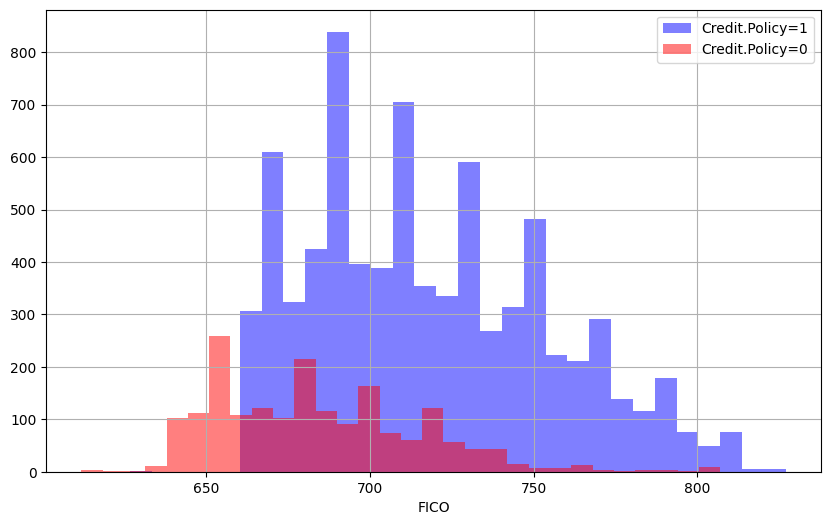

In [27]:
plt.figure(figsize=(10,6))
loans[loans['credit.policy']==1]['fico'].hist(alpha=0.5,color='blue',
                                              bins=30,label='Credit.Policy=1')
loans[loans['credit.policy']==0]['fico'].hist(alpha=0.5,color='red',
                                              bins=30,label='Credit.Policy=0')
plt.legend()
plt.xlabel('FICO')

Interpret the result of the graph

The graph shows the distribution of credit transactions grouped into two, including following and not following the credit policies. The distributions shows that most of the recorded transactions follow the credit policy, and populated the lower to higher FICO score ranges. Less records of transactions that do not follow the credit policy were seen, as well as populating the lower FICO score ranges. This simply indicates that transactions that follow the credit policy are more likely to be accepted for loan and to repay their loans on time.

Create a similar figure, except this time select by the not.fully.paid column.

Text(0.5, 0, 'FICO')

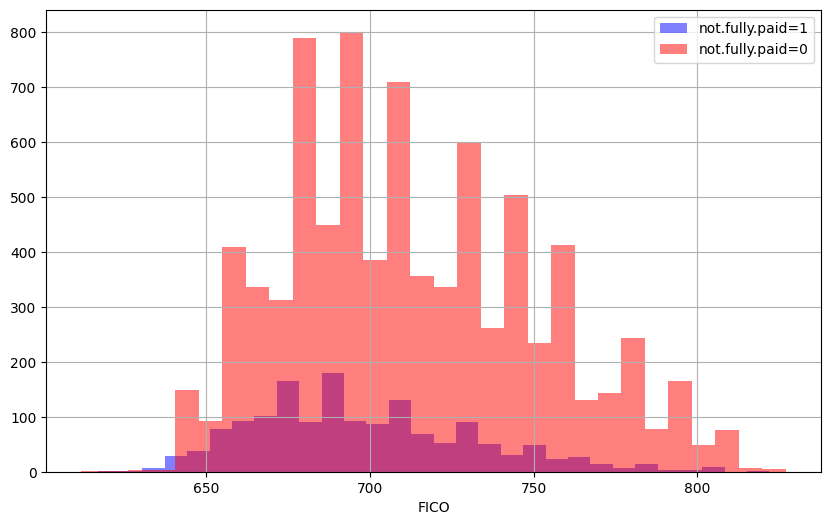

In [28]:
plt.figure(figsize=(10,6))
loans[loans['not.fully.paid']==1]['fico'].hist(alpha=0.5,color='blue',
                                              bins=30,label='not.fully.paid=1')
loans[loans['not.fully.paid']==0]['fico'].hist(alpha=0.5,color='red',
                                              bins=30,label='not.fully.paid=0')
plt.legend()
plt.xlabel('FICO')

Interpret the result of the graph

The graph shows the distribution between lenders that are fully paid and not fully paid. Many lenders in the dataset are still not fully paid, and just a portion were fully paid. Lenders with FICO scores from 650 to 750 indicate higher distribution.

Create a countplot using seaborn showing the counts of loans by purpose, with the color hue defined by not.fully.paid.

<Axes: xlabel='purpose', ylabel='count'>

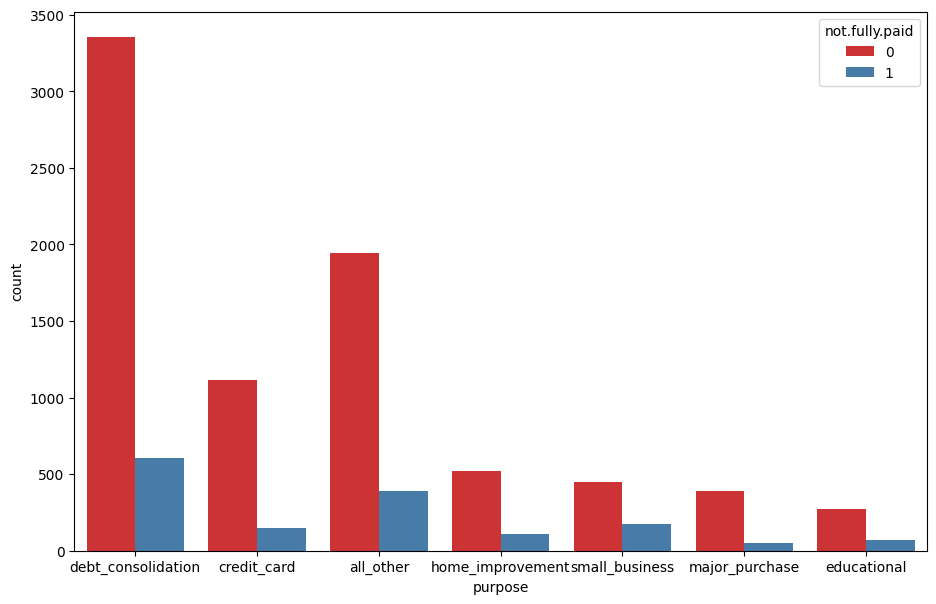

In [29]:
plt.figure(figsize=(11,7))
sns.countplot(x='purpose',hue='not.fully.paid',data=loans,palette='Set1')

Interpret the result of the graph.

The bar graph shows the specific distribution of lenders that are fully paid and not fully paid, where it indicates the  lending purpose. Lenders with debt consolidation indicate the highest count, followed by credit card and other purposes. Based on the definition of debt consolidation, it involves a lower interest rate, making it a popular choice for lenders.

Create the following lmplots to see if the trend differed between not.fully.paid and credit.policy.

<Figure size 1100x700 with 0 Axes>

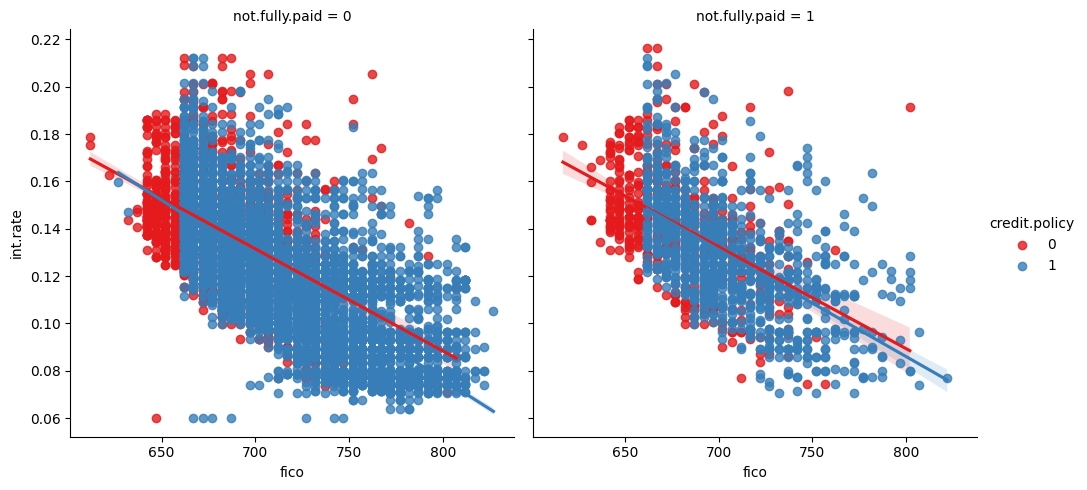

In [30]:
plt.figure(figsize=(11,7))
sns.lmplot(y='int.rate',x='fico',data=loans,hue='credit.policy',
           col='not.fully.paid',palette='Set1')

Interpret the result of the graph

The graph simply indicates that lenders, fully paid or not fully paid, are more likely to accept loans having interest rates from 12% to 18%. The lenders that are not fully paid also have FICO scores from 650-800, while fully paid lenders have FICO scores from 650-750.

The **purpose** column contains categorical value. Therefore, we need to transform the data using dummy variables.
otice that the **purpose** column as categorical



In [31]:
cat_feats = ['purpose']

In [32]:
final_data = pd.get_dummies(loans,columns=cat_feats,drop_first=True)

In [33]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   credit.policy               9578 non-null   int64  
 1   int.rate                    9578 non-null   float64
 2   installment                 9578 non-null   float64
 3   log.annual.inc              9578 non-null   float64
 4   dti                         9578 non-null   float64
 5   fico                        9578 non-null   int64  
 6   days.with.cr.line           9578 non-null   float64
 7   revol.bal                   9578 non-null   int64  
 8   revol.util                  9578 non-null   float64
 9   inq.last.6mths              9578 non-null   int64  
 10  delinq.2yrs                 9578 non-null   int64  
 11  pub.rec                     9578 non-null   int64  
 12  not.fully.paid              9578 non-null   int64  
 13  purpose_credit_card         9578 

Split the data into a training set and a testing set

In [34]:
from sklearn.model_selection import train_test_split

In [35]:
X = final_data.drop('not.fully.paid',axis=1)
y = final_data['not.fully.paid']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

Create an instance of the RandomForestClassifier class and fit it to our training data

In [36]:
from sklearn.ensemble import RandomForestClassifier

In [37]:
rfc = RandomForestClassifier(n_estimators=600)

In [38]:
rfc.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

What is n_estimators?

The n_estimators argument in RandomForestClassifier indicates the number of decision trees that will be made from the ensemble training. It is important to indicate the right amount of estimators to avoid overfitting.

Predict the class of not.fully.paid for the X_test data.

In [39]:
predictions = rfc.predict(X_test)

Create a classification report from the results

In [40]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score, roc_auc_score

In [41]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      2431
           1       0.47      0.02      0.04       443

    accuracy                           0.85      2874
   macro avg       0.66      0.51      0.48      2874
weighted avg       0.79      0.85      0.78      2874



Show the Confusion Matrix for the predictions.

In [42]:
print(confusion_matrix(y_test,predictions))

[[2421   10]
 [ 434    9]]


In [43]:
#evaluate the performance using accuracy score
print(accuracy_score(y_test, predictions))

0.8455114822546973


In [44]:
print(roc_auc_score(y_test, predictions))

0.5081012467813689


Interpret the result of the classification error, confusion matrix , accuracy score and roc_auc_score

The results presented the model accuracy of classifying the 2 main classes in the dataset: lenders that are fully paid and not fully paid. Fully paid lenders were predicted with high precision (0.85), perfect recall (1.00), and a high F1-score (0.92). This means it is great  at identifying loans that were fully paid. Not fully paid lenders had poor performance, with low precision (0.47), extremely low recall (0.02), and a very low F1-score (0.04). This indicates that the model struggles significantly to identify loans that were not fully paid, catching only 2% of them. The overall accuracy is 0.85 (85%). While seemingly high, this can be considered as misleading due to the significant class imbalance and unequal performance on predicting both classes.

The Confusion Matrix indicated that the model correctly predicted 2421 loans as 'fully paid', incorrectly predicted 10 loans as 'fully paid' when they were actually 'not fully paid', incorrectly predicted 434 loans as 'not fully paid' when they were actually 'fully paid', and correctly predicted only 9 loans as 'not fully paid'.

The ROC AUC score is approximately 0.5081.This is a strong indicator that the model is not effective at predicting which loans will not be fully paid.

Supplementary Activity:
* Choose your own dataset
* Import the dataset
* Determine the number of datapoints, columns and data types
* Remove unneccesary columns
* Do data cleaning such as removing empty values(NaN), replacing missing data .
* Perform descriptive statistics such as mean, median and mode
* Perform data visualization
* Build the model using Ranfom Forest
* Evaluate the model using classification report, accuracy , confusion matrix and roc_auc_score
* Change the n_estimators from 100 to 1000, increment by 100.
* Create a graph to compare the accuracy based from n_estimators

Dataset: [Penguin Species Dataset](https://www.kaggle.com/datasets/srisyra02/penguin-species-dataset/data)

Importing dataset

In [45]:
# Importing dataset
df = pd.read_csv("penguins.csv")
df.head(5)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [46]:
# Data points
print(f"Data Points: {df.shape[0]}\nColumns: {df.shape[1]}")

Data Points: 1000
Columns: 7


In [47]:
# Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   object 
 1   island             1000 non-null   object 
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    object 
dtypes: float64(4), object(3)
memory usage: 54.8+ KB


In [48]:
# Data types
df.dtypes

,0
species,object
island,object
culmen_length_mm,float64
culmen_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


In [49]:
# Describe
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,990.000000,990.000000,990.000000,990.000000
mean,43.817778,17.335556,199.224242,4103.311111
std,5.309985,1.779057,13.171660,705.334794
min,32.400000,13.000000,175.000000,2830.000000
25%,39.000000,15.800000,189.000000,3586.000000
50%,43.800000,17.800000,195.000000,3882.000000
75%,48.300000,18.700000,212.000000,4587.000000
max,56.000000,21.400000,235.000000,6317.000000


Data Cleaning

In [50]:
# Create copy
df_clean = df.copy()

# Clean missing rows
df_clean = df.dropna()

df_clean.shape

(951, 7)

In [51]:
# Get numerical columns
dfc_numeric = df_clean.select_dtypes(include='number')

In [52]:
# Mean
dfc_numeric.mean()

,0
culmen_length_mm,43.825026
culmen_depth_mm,17.324711
flipper_length_mm,199.191377
body_mass_g,4096.220820


In [53]:
# Median
dfc_numeric.median()

,0
culmen_length_mm,43.9
culmen_depth_mm,17.8
flipper_length_mm,195.0
body_mass_g,3880.0


In [54]:
# Mode
dfc_numeric.mode()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,38.3,18.2,189.0,3318.0
1,NaN,NaN,NaN,3540.0
2,NaN,NaN,NaN,3710.0
3,NaN,NaN,NaN,3755.0


In [55]:
# Clean df
df_clean.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


Data visualization

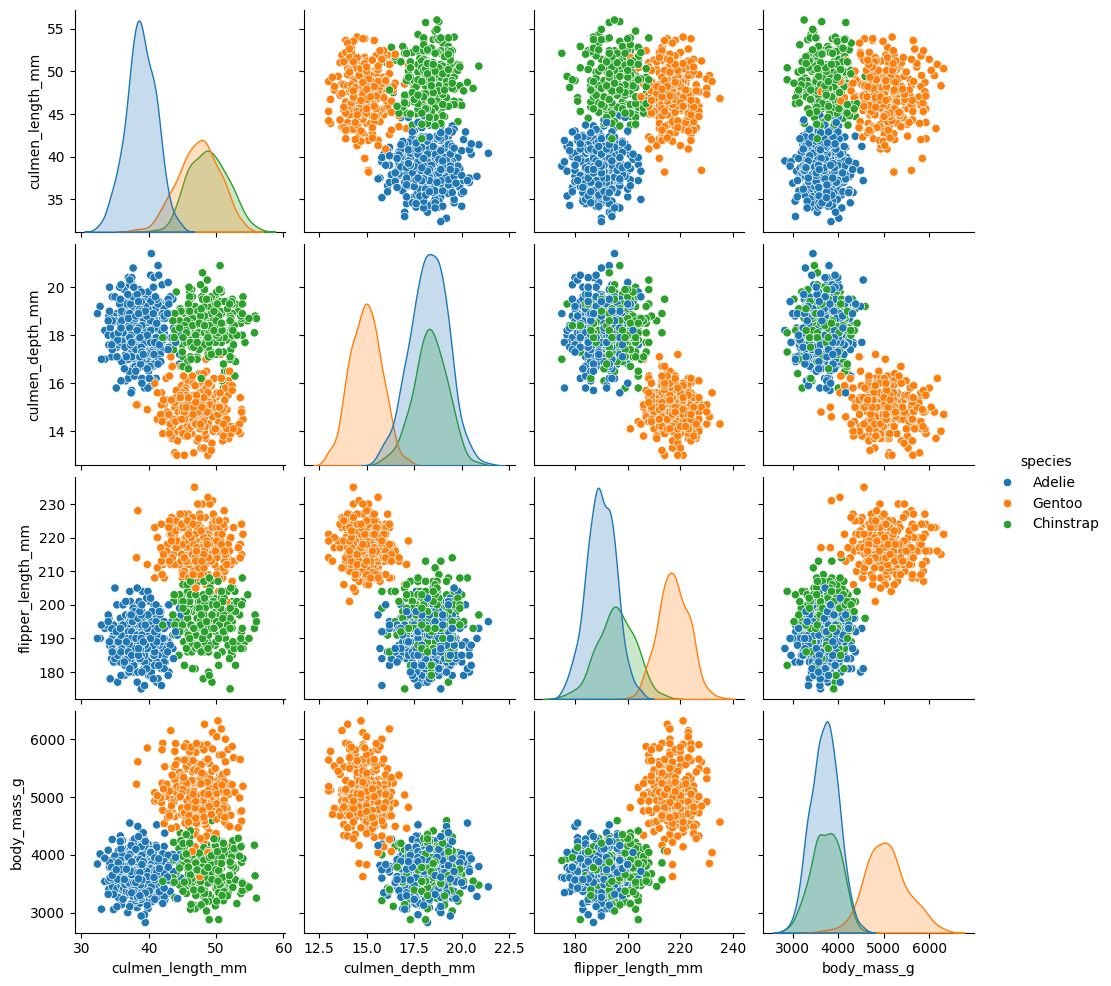

In [56]:
sns.pairplot(data=df_clean, hue="species")
plt.show()

In [81]:
# convert species to numerical
df_clean['species'] = df_clean['species'].map({'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2})

/tmp/ipykernel_2645/2668828828.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['species'] = df_clean['species'].map({'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2})


In [83]:
X = df_clean.drop(['species', 'island', 'sex'],axis=1)
y = df_clean['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

Create an instance of the RandomForestClassifier class and fit it to our training data

In [85]:
rfc = RandomForestClassifier(n_estimators=600)

In [86]:
rfc.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

What is n_estimators?

Type your answer here

Predict the class of not.fully.paid for the X_test data.

In [87]:
predictions = rfc.predict(X_test)

Create a classification report from the results

In [88]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score, roc_auc_score

In [89]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       120
           1       0.99      0.99      0.99        77
           2       1.00      1.00      1.00        89

    accuracy                           0.99       286
   macro avg       0.99      0.99      0.99       286
weighted avg       0.99      0.99      0.99       286



Show the Confusion Matrix for the predictions.

In [90]:
print(confusion_matrix(y_test,predictions))

[[119   1   0]
 [  1  76   0]
 [  0   0  89]]


In [91]:
#evaluate the performance using accuracy score
print(accuracy_score(y_test, predictions))

0.993006993006993


In [94]:
print(roc_auc_score(y_test, rfc.predict_proba(X_test), multi_class='ovr'))

0.9999625534595559


Conclusion

The activity demonstrated the application of the Random Forest Classifier model to a loan dataset. The data was initially analyzed to learn more about the data. A Random Forest Classifier was then applied to it. Upon predicting on the test set, the model yielded a high overall accuracy of about 85%. However, a detailed evaluation using the classification report, confusion matrix, and ROC AUC score revealed significant limitations: while performing well on 'fully paid' loans, it struggled severely with the minority class of 'not fully paid' loans.

The supplementary activity demonstated the usage of Random Forest Classifier to the penguin species dataset. The model achieved a high accuracy of 99.3%, demonstrating excellent performance in classifying the different penguin species. The precision, recall, and F1-score for each species were also very high, ranging from 99% to 100%,. The ROC AUC score further supports this, with a value of 0.9999. This indicates how the Random Forest Classifier was appropriate to the dataset, showing robust and reliable results.